# Week 04 — YCB-V Object Classification II

**Group 1 | Main Quest: Improving Deep Neural Networks**  
**Side Quest: Object Classification II**

This notebook is a direct continuation of the Week 03 baseline. It keeps the **same YCB-V BOP'19 subset, selected classes, object crops, scene-level split, image size, and MLP family** so Week 04 changes can be compared fairly.

Week 03 measured baseline:

- selected classes: `tomato_soup_can`, `sugar_box`, `master_chef_can`, `tuna_fish_can`, `bleach_cleanser`
- train / validation / test samples: **877 / 375 / 450**
- train / validation / test scenes: **8 / 2 / 2**
- best validation loss: **0.0516**
- best validation accuracy: **0.9813**
- test accuracy: **0.5133**

The large validation-to-test gap is the main Week 04 motivation: improve generalization without changing the task or leaking test information into model selection.

## 0. Week 04 objectives and experiment rules

Required Week 04 topics are implemented explicitly:

1. **Regularization** — dropout and L2-style weight decay.
2. **Data augmentation** — moderate geometric and color transformations on training crops only.
3. **Optimizer experiments** — Adam, AdamW, and SGD with momentum.
4. **Learning-rate experiments** — controlled LR changes while the rest of the setup is held fixed as much as possible.
5. **Hyperparameter tuning** — a small, interpretable experiment table rather than a blind search.
6. **Curves + comparison table + interpretation** — saved automatically.

### Evaluation rule
The **test set is not used to choose an experiment**. Experiments are ranked using validation loss/accuracy. Only the final selected model is evaluated on the test set.

## 1. Install and import

Run the notebook in Google Colab if the YCB-V subset is not already present locally. The first run may download the same ~660 MB BOP'19 test subset used in Week 03.

In [1]:
%pip -q install huggingface_hub pillow matplotlib pandas scikit-learn torch torchvision python-docx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 4.7 MB/s eta 0:00:00


In [2]:
from pathlib import Path
import json
import random
import math
import zipfile
import copy
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from huggingface_hub import hf_hub_download

SEED = 42

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cpu


## 2. Configuration

The data definition is intentionally identical to Week 03. Week 04 changes only training-time choices.

In [3]:
DATASETS_DIR = Path("datasets")
DOWNLOAD_DIR = DATASETS_DIR / "downloads"
DATASET_ROOT = DATASETS_DIR / "ycbv"
OUTPUT_DIR = Path("outputs/week04")
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"

N_CLASSES = 5
IMAGE_SIZE = 64
BATCH_SIZE = 64
MAX_EPOCHS = 20
EARLY_STOPPING_PATIENCE = 5

MIN_VISIBILITY = 0.35
MIN_BOX_SIDE = 24
MAX_TRAIN_PER_CLASS = 600
MAX_VAL_PER_CLASS = 150
MAX_TEST_PER_CLASS = 150

WEEK3_BASELINE = {
    "experiment": "week03_baseline_reference",
    "optimizer": "Adam",
    "learning_rate": 1e-3,
    "dropout": 0.0,
    "weight_decay": 0.0,
    "augmentation": False,
    "best_epoch": 2,
    "best_val_loss": 0.0516,
    "best_val_accuracy": 0.9813,
    "test_accuracy": 0.5133,
}

for p in [DOWNLOAD_DIR, DATASET_ROOT, OUTPUT_DIR, CHECKPOINT_DIR]:
    p.mkdir(parents=True, exist_ok=True)

print("Dataset root:", DATASET_ROOT.resolve())
print("Output dir:", OUTPUT_DIR.resolve())

Dataset root: /content/datasets/ycbv
Output dir: /content/outputs/week04


## 3. Download / reuse the exact Week 03 YCB-V subset

If `datasets/ycbv/test` already exists, downloading is skipped.

In [4]:
REPO_ID = "bop-benchmark/ycbv"

def download_hf(filename):
    try:
        return Path(hf_hub_download(repo_id=REPO_ID, filename=filename, repo_type="dataset"))
    except Exception:
        return Path(hf_hub_download(repo_id=REPO_ID, filename=filename))

def dataset_ready(root):
    test_dir = root / "test"
    return test_dir.exists() and any(test_dir.iterdir())

if not dataset_ready(DATASET_ROOT):
    base_zip = download_hf("ycbv_base.zip")
    test_zip = download_hf("ycbv_test_bop19.zip")

    print("Extracting base archive...")
    with zipfile.ZipFile(base_zip, "r") as zf:
        zf.extractall(DATASET_ROOT)

    print("Extracting BOP'19 test subset...")
    with zipfile.ZipFile(test_zip, "r") as zf:
        zf.extractall(DATASET_ROOT)
else:
    print("Dataset already exists. Download skipped.")

print("Ready:", dataset_ready(DATASET_ROOT))

ycbv_base.zip: reconstructing file:   0%|          |  0.00B / 15.8kB            

ycbv_base.zip: downloading bytes:           |  0.00B            

ycbv_test_bop19.zip: reconstructing file:   0%|          |  0.00B /  660MB            

ycbv_test_bop19.zip: downloading bytes:           |  0.00B            

Extracting base archive...
Extracting BOP'19 test subset...
Ready: True


## 4. Rebuild the same object-instance table and selected classes

This section is copied conceptually from Week 03 so the task definition does not move between weeks.

In [5]:
YCBV_OBJECTS = {
    1: "master_chef_can", 2: "cracker_box", 3: "sugar_box", 4: "tomato_soup_can",
    5: "mustard_bottle", 6: "tuna_fish_can", 7: "pudding_box", 8: "gelatin_box",
    9: "potted_meat_can", 10: "banana", 11: "pitcher_base", 12: "bleach_cleanser",
    13: "bowl", 14: "mug", 15: "power_drill", 16: "wood_block", 17: "scissors",
    18: "large_marker", 19: "large_clamp", 20: "extra_large_clamp", 21: "foam_brick",
}

def load_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)

def build_instance_table(dataset_root):
    test_root = dataset_root / "test"
    rows = []
    scene_dirs = sorted([p for p in test_root.iterdir() if p.is_dir()])
    for scene_dir in scene_dirs:
        scene_id = int(scene_dir.name)
        gt = load_json(scene_dir / "scene_gt.json")
        info = load_json(scene_dir / "scene_gt_info.json")
        for im_key, objects in gt.items():
            infos = info[im_key]
            im_id = int(im_key)
            rgb_path = scene_dir / "rgb" / f"{im_id:06d}.png"
            if not rgb_path.exists():
                jpg_path = scene_dir / "rgb" / f"{im_id:06d}.jpg"
                rgb_path = jpg_path if jpg_path.exists() else rgb_path
            for instance_idx, (obj, obj_info) in enumerate(zip(objects, infos)):
                obj_id = int(obj["obj_id"])
                bbox = obj_info.get("bbox_obj") or obj_info.get("bbox_visib")
                visibility = float(obj_info.get("visib_fract", 1.0))
                if bbox is None:
                    continue
                x, y, w, h = [int(round(v)) for v in bbox]
                if w < MIN_BOX_SIDE or h < MIN_BOX_SIDE or visibility < MIN_VISIBILITY or not rgb_path.exists():
                    continue
                rows.append({
                    "scene_id": scene_id, "im_id": im_id, "instance_idx": instance_idx,
                    "obj_id": obj_id, "class_name": YCBV_OBJECTS.get(obj_id, f"obj_{obj_id:02d}"),
                    "x": x, "y": y, "w": w, "h": h,
                    "visib_fract": visibility, "rgb_path": str(rgb_path),
                })
    return pd.DataFrame(rows)

instances_df = build_instance_table(DATASET_ROOT)
print("Usable object instances:", len(instances_df))

class_stats = (
    instances_df.groupby(["obj_id", "class_name"])
    .agg(samples=("obj_id", "size"), scenes=("scene_id", "nunique"), mean_visibility=("visib_fract", "mean"))
    .reset_index().sort_values(["scenes", "samples"], ascending=False)
)

eligible = class_stats[class_stats["scenes"] >= 3].copy()
if len(eligible) < N_CLASSES:
    raise RuntimeError("Not enough classes with >=3 scenes. Keep Week 03 data/filter settings unchanged.")

selected_stats = eligible.head(N_CLASSES).copy()
SELECTED_OBJ_IDS = selected_stats["obj_id"].tolist()
SELECTED_NAMES = selected_stats["class_name"].tolist()
selected_df = instances_df[instances_df["obj_id"].isin(SELECTED_OBJ_IDS)].copy()

display(selected_stats)
print("Selected classes:", SELECTED_NAMES)
selected_stats.to_csv(OUTPUT_DIR / "selected_class_stats.csv", index=False)

Usable object instances: 4099


,obj_id,class_name,samples,scenes,mean_visibility
3,4,tomato_soup_can,427,6,0.957412
2,3,sugar_box,375,5,0.889261
0,1,master_chef_can,300,4,0.899518
5,6,tuna_fish_can,300,4,0.998461
11,12,bleach_cleanser,300,4,0.875803


Selected classes: ['tomato_soup_can', 'sugar_box', 'master_chef_can', 'tuna_fish_can', 'bleach_cleanser']


## 5. Recreate the same scene-level train / validation / test split

All samples from a scene remain in one split. This avoids obvious frame-level leakage.

In [6]:
def all_classes_present(df, obj_ids):
    return set(obj_ids).issubset(set(df["obj_id"].unique().tolist()))

def find_scene_split(df, obj_ids, train_frac=0.70, val_frac=0.15, attempts=5000):
    scenes = np.array(sorted(df["scene_id"].unique()))
    n = len(scenes)
    n_test = max(1, int(round(n * (1 - train_frac - val_frac))))
    n_val = max(1, int(round(n * val_frac)))
    n_train = n - n_val - n_test

    for attempt in range(attempts):
        rng = np.random.default_rng(SEED + attempt)
        shuffled = rng.permutation(scenes)
        train_scenes = set(shuffled[:n_train])
        val_scenes = set(shuffled[n_train:n_train + n_val])
        test_scenes = set(shuffled[n_train + n_val:])
        train_df = df[df["scene_id"].isin(train_scenes)]
        val_df = df[df["scene_id"].isin(val_scenes)]
        test_df = df[df["scene_id"].isin(test_scenes)]
        if all_classes_present(train_df, obj_ids) and all_classes_present(val_df, obj_ids) and all_classes_present(test_df, obj_ids):
            return train_df.copy(), val_df.copy(), test_df.copy()
    raise RuntimeError("Could not reproduce a valid scene-level split.")

def cap_per_class(df, max_per_class, seed):
    parts = []
    for obj_id, group in df.groupby("obj_id"):
        n = min(len(group), max_per_class)
        parts.append(group.sample(n=n, random_state=seed))
    return pd.concat(parts, ignore_index=True).sample(frac=1, random_state=seed).reset_index(drop=True)

train_df, val_df, test_df = find_scene_split(selected_df, SELECTED_OBJ_IDS)
train_df = cap_per_class(train_df, MAX_TRAIN_PER_CLASS, SEED)
val_df = cap_per_class(val_df, MAX_VAL_PER_CLASS, SEED)
test_df = cap_per_class(test_df, MAX_TEST_PER_CLASS, SEED)

for name, df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{name}: {len(df)} samples | {df['scene_id'].nunique()} scenes")
    display(df.groupby(["obj_id", "class_name"]).size().rename("samples").reset_index())

assert set(train_df["scene_id"]).isdisjoint(set(val_df["scene_id"]))
assert set(train_df["scene_id"]).isdisjoint(set(test_df["scene_id"]))
assert set(val_df["scene_id"]).isdisjoint(set(test_df["scene_id"]))

split_summary = pd.concat([
    train_df.assign(split="train"), val_df.assign(split="val"), test_df.assign(split="test")
], ignore_index=True)
split_summary.to_csv(OUTPUT_DIR / "split_summary.csv", index=False)

expected_counts = (877, 375, 450)
actual_counts = (len(train_df), len(val_df), len(test_df))
print("Expected Week 03 counts:", expected_counts)
print("Current counts:", actual_counts)
if actual_counts != expected_counts:
    print("WARNING: counts differ from the Week 03 run. Check dataset version/filter settings before interpreting comparisons.")
else:
    print("Week 03 split size successfully reproduced.")

train: 877 samples | 8 scenes


,obj_id,class_name,samples
0,1,master_chef_can,150
1,3,sugar_box,225
2,4,tomato_soup_can,202
3,6,tuna_fish_can,150
4,12,bleach_cleanser,150


val: 375 samples | 2 scenes


,obj_id,class_name,samples
0,1,master_chef_can,75
1,3,sugar_box,75
2,4,tomato_soup_can,75
3,6,tuna_fish_can,75
4,12,bleach_cleanser,75


test: 450 samples | 2 scenes


,obj_id,class_name,samples
0,1,master_chef_can,75
1,3,sugar_box,75
2,4,tomato_soup_can,150
3,6,tuna_fish_can,75
4,12,bleach_cleanser,75


Expected Week 03 counts: (877, 375, 450)
Current counts: (877, 375, 450)
Week 03 split size successfully reproduced.


## 6. Crop function and augmentation preview

Augmentation is applied **only to training crops**. Validation and test always use deterministic preprocessing.

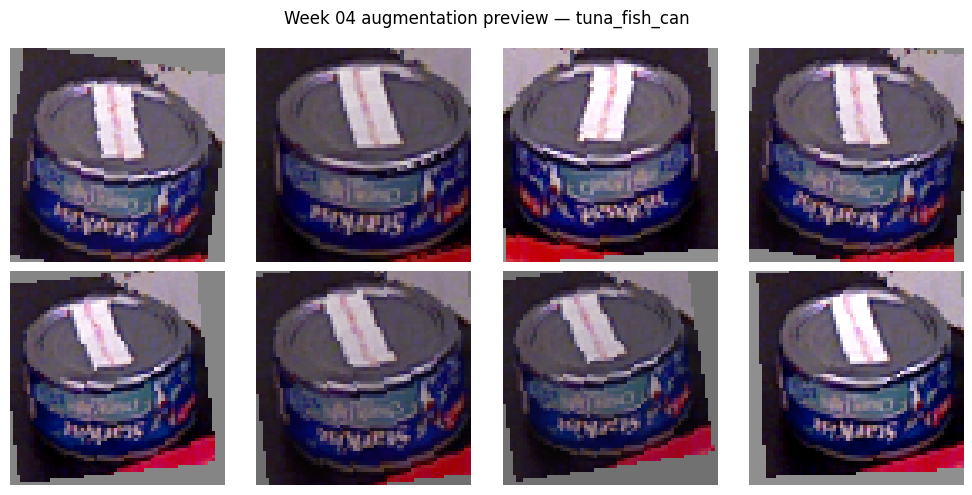

In [7]:
def crop_object(row, padding=0.08):
    image = Image.open(row["rgb_path"]).convert("RGB")
    W, H = image.size
    x, y, w, h = int(row["x"]), int(row["y"]), int(row["w"]), int(row["h"])
    pad_x, pad_y = int(w * padding), int(h * padding)
    left, top = max(0, x - pad_x), max(0, y - pad_y)
    right, bottom = min(W, x + w + pad_x), min(H, y + h + pad_y)
    return image.crop((left, top, right, bottom))

NORMALIZE = transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    NORMALIZE,
])

augment_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomAffine(
        degrees=10,
        translate=(0.05, 0.05),
        scale=(0.90, 1.10),
        fill=(128, 128, 128),
    ),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10, hue=0.03),
    transforms.ToTensor(),
    NORMALIZE,
])

sample_row = train_df.iloc[0]
sample_crop = crop_object(sample_row)
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for ax in axes.ravel():
    aug = augment_transform(sample_crop)
    aug = (aug * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0).numpy()
    ax.imshow(aug)
    ax.axis("off")
plt.suptitle(f"Week 04 augmentation preview — {sample_row['class_name']}")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "augmentation_preview.png", dpi=160, bbox_inches="tight")
plt.show()

## 7. Dataset, loaders, and regularized MLP

The MLP family stays the same as Week 03. Dropout is parameterized so regularization can be tested without introducing convolutional layers.

In [8]:
label_map = {obj_id: i for i, obj_id in enumerate(SELECTED_OBJ_IDS)}
class_names = [YCBV_OBJECTS[obj_id] for obj_id in SELECTED_OBJ_IDS]

class YCBVCropDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        x = self.transform(crop_object(row))
        y = label_map[int(row["obj_id"])]
        return x, y

class RegularizedMLP(nn.Module):
    def __init__(self, image_size, n_classes, dropout=0.0):
        super().__init__()
        input_dim = 3 * image_size * image_size
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, n_classes),
        )
    def forward(self, x):
        return self.net(x)

def make_loaders(use_augmentation):
    train_transform = augment_transform if use_augmentation else eval_transform
    train_ds = YCBVCropDataset(train_df, train_transform)
    val_ds = YCBVCropDataset(val_df, eval_transform)
    test_ds = YCBVCropDataset(test_df, eval_transform)

    g = torch.Generator()
    g.manual_seed(SEED)
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, generator=g)
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    return train_ds, val_ds, test_ds, train_loader, val_loader, test_loader

## 8. Controlled Week 04 experiment table

The sequence is intentionally interpretable:

- **E1** adds regularization only.
- **E2** adds augmentation on top of E1.
- **E3** changes learning rate while keeping E2 choices.
- **E4** changes optimizer to AdamW.
- **E5** compares SGD + momentum.

This is a small manual hyperparameter study, not an exhaustive grid search.

In [9]:
EXPERIMENTS = [
    {
        "name": "E1_regularization",
        "optimizer": "adam", "lr": 1e-3,
        "dropout": 0.30, "weight_decay": 1e-4,
        "augmentation": False,
    },
    {
        "name": "E2_regularization_plus_augmentation",
        "optimizer": "adam", "lr": 1e-3,
        "dropout": 0.30, "weight_decay": 1e-4,
        "augmentation": True,
    },
    {
        "name": "E3_lower_lr",
        "optimizer": "adam", "lr": 3e-4,
        "dropout": 0.30, "weight_decay": 1e-4,
        "augmentation": True,
    },
    {
        "name": "E4_adamw",
        "optimizer": "adamw", "lr": 3e-4,
        "dropout": 0.30, "weight_decay": 1e-4,
        "augmentation": True,
    },
    {
        "name": "E5_sgd_momentum",
        "optimizer": "sgd", "lr": 1e-2,
        "dropout": 0.30, "weight_decay": 1e-4,
        "augmentation": True,
        "momentum": 0.9,
    },
]

pd.DataFrame(EXPERIMENTS)

,name,optimizer,lr,dropout,weight_decay,augmentation,momentum
0,E1_regularization,adam,0.0010,0.3,0.0001,False,NaN
1,E2_regularization_plus_augmentation,adam,0.0010,0.3,0.0001,True,NaN
2,E3_lower_lr,adam,0.0003,0.3,0.0001,True,NaN
3,E4_adamw,adamw,0.0003,0.3,0.0001,True,NaN
4,E5_sgd_momentum,sgd,0.0100,0.3,0.0001,True,0.9


## 9. Training utilities

All experiments use the same loss, batch size, split, maximum epochs, and early-stopping rule. Checkpoints are selected by **validation loss**.

In [10]:
criterion = nn.CrossEntropyLoss()

def make_optimizer(model, cfg):
    name = cfg["optimizer"].lower()
    if name == "adam":
        return torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    if name == "adamw":
        return torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    if name == "sgd":
        return torch.optim.SGD(
            model.parameters(), lr=cfg["lr"], momentum=cfg.get("momentum", 0.0),
            weight_decay=cfg["weight_decay"]
        )
    raise ValueError(name)

def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, total = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        if training:
            optimizer.zero_grad()
        logits = model(x)
        loss = criterion(logits, y)
        if training:
            loss.backward()
            optimizer.step()
        total_loss += loss.item() * x.size(0)
        correct += (logits.argmax(dim=1) == y).sum().item()
        total += y.size(0)
    return total_loss / total, correct / total

def train_experiment(cfg):
    seed_everything(SEED)
    _, _, _, train_loader, val_loader, _ = make_loaders(cfg["augmentation"])
    model = RegularizedMLP(IMAGE_SIZE, N_CLASSES, dropout=cfg["dropout"]).to(DEVICE)
    optimizer = make_optimizer(model, cfg)
    ckpt_path = CHECKPOINT_DIR / f"{cfg['name']}.pt"

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_loss = float("inf")
    best_val_acc = 0.0
    best_epoch = 0
    epochs_without_improvement = 0

    for epoch in range(1, MAX_EPOCHS + 1):
        train_loss, train_acc = run_epoch(model, train_loader, optimizer)
        val_loss, val_acc = run_epoch(model, val_loader, None)
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        improved = val_loss < best_val_loss - 1e-6
        if improved:
            best_val_loss = val_loss
            best_val_acc = val_acc
            best_epoch = epoch
            epochs_without_improvement = 0
            torch.save(model.state_dict(), ckpt_path)
        else:
            epochs_without_improvement += 1

        print(
            f"{cfg['name']} | epoch {epoch:02d}/{MAX_EPOCHS} | "
            f"train loss {train_loss:.4f} acc {train_acc:.3f} | "
            f"val loss {val_loss:.4f} acc {val_acc:.3f}"
        )
        if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
            print("Early stopping.")
            break

    best_idx = best_epoch - 1
    return {
        **cfg,
        "best_epoch": best_epoch,
        "best_val_loss": float(best_val_loss),
        "best_val_accuracy": float(best_val_acc),
        "train_acc_at_best": float(history["train_acc"][best_idx]),
        "train_loss_at_best": float(history["train_loss"][best_idx]),
        "generalization_gap_at_best": float(history["train_acc"][best_idx] - best_val_acc),
        "epochs_ran": len(history["val_loss"]),
        "checkpoint": str(ckpt_path),
        "history": history,
    }

## 10. Run all Week 04 experiments

On CPU this may take longer; Colab GPU is recommended. Results are saved after each completed experiment.

In [11]:
experiment_results = []
for cfg in EXPERIMENTS:
    print("\n" + "=" * 90)
    print("Running", cfg["name"])
    result = train_experiment(cfg)
    experiment_results.append(result)

results_df = pd.DataFrame([
    {k: v for k, v in r.items() if k != "history"}
    for r in experiment_results
])
results_df.to_csv(OUTPUT_DIR / "week04_experiment_results.csv", index=False)
display(results_df[[
    "name", "optimizer", "lr", "dropout", "weight_decay", "augmentation",
    "best_epoch", "best_val_loss", "best_val_accuracy", "train_acc_at_best",
    "generalization_gap_at_best", "epochs_ran"
]].sort_values("best_val_loss"))


Running E1_regularization
E1_regularization | epoch 01/20 | train loss 0.2491 acc 0.902 | val loss 0.3794 acc 0.920
E1_regularization | epoch 02/20 | train loss 0.0177 acc 0.994 | val loss 0.1798 acc 0.976
E1_regularization | epoch 03/20 | train loss 0.0137 acc 0.997 | val loss 0.8530 acc 0.821
E1_regularization | epoch 04/20 | train loss 0.0051 acc 0.997 | val loss 0.4970 acc 0.915
E1_regularization | epoch 05/20 | train loss 0.0028 acc 0.999 | val loss 0.3734 acc 0.923
E1_regularization | epoch 06/20 | train loss 0.0095 acc 0.997 | val loss 0.0639 acc 0.984
E1_regularization | epoch 07/20 | train loss 0.0002 acc 1.000 | val loss 0.0327 acc 0.989
E1_regularization | epoch 08/20 | train loss 0.0007 acc 1.000 | val loss 0.0404 acc 0.987
E1_regularization | epoch 09/20 | train loss 0.0003 acc 1.000 | val loss 0.0383 acc 0.987
E1_regularization | epoch 10/20 | train loss 0.0003 acc 1.000 | val loss 0.0484 acc 0.987
E1_regularization | epoch 11/20 | train loss 0.0000 acc 1.000 | val loss 

,name,optimizer,lr,dropout,weight_decay,augmentation,best_epoch,best_val_loss,best_val_accuracy,train_acc_at_best,generalization_gap_at_best,epochs_ran
0,E1_regularization,adam,0.0010,0.3,0.0001,False,7,0.032718,0.989333,1.000000,0.010667,12
1,E2_regularization_plus_augmentation,adam,0.0010,0.3,0.0001,True,4,0.063640,0.978667,0.988597,0.009931,9
2,E3_lower_lr,adam,0.0003,0.3,0.0001,True,10,0.081510,0.968000,0.997719,0.029719,15
3,E4_adamw,adamw,0.0003,0.3,0.0001,True,2,0.097444,0.976000,0.962372,-0.013628,7
4,E5_sgd_momentum,sgd,0.0100,0.3,0.0001,True,3,0.129741,0.941333,0.950969,0.009636,8


## 11. Training curves and comparison plots

Each experiment gets its own loss/accuracy figure, plus one cross-experiment validation comparison.

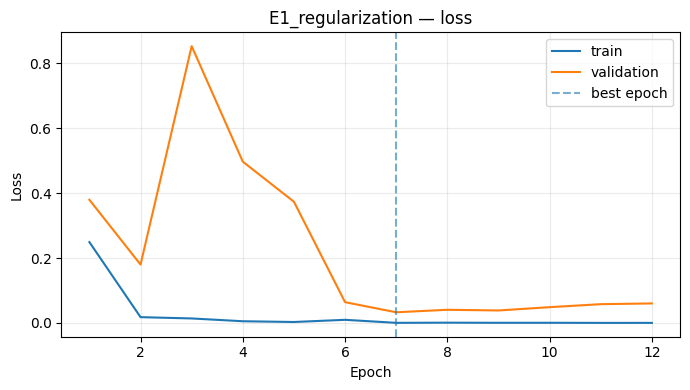

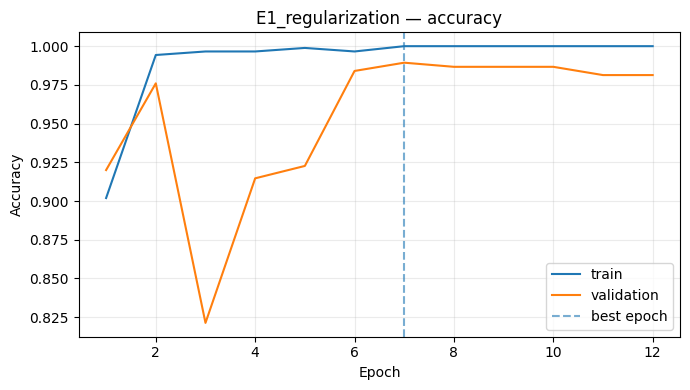

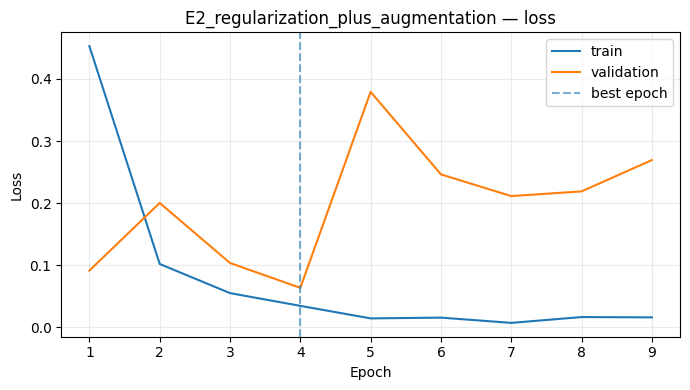

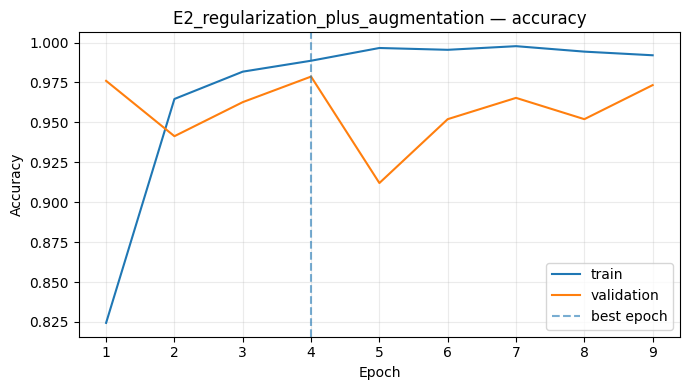

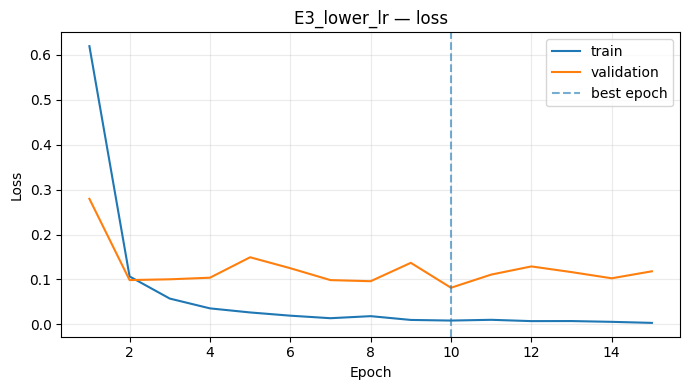

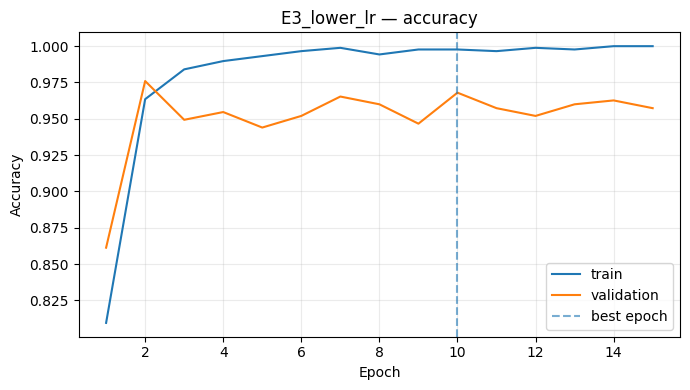

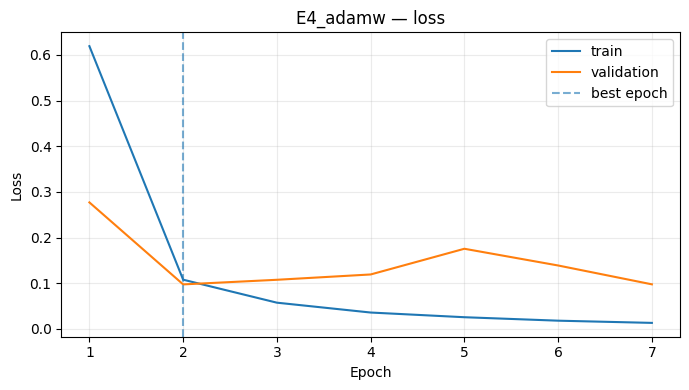

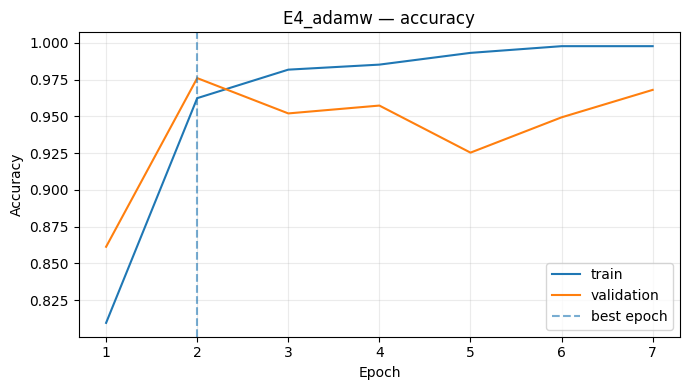

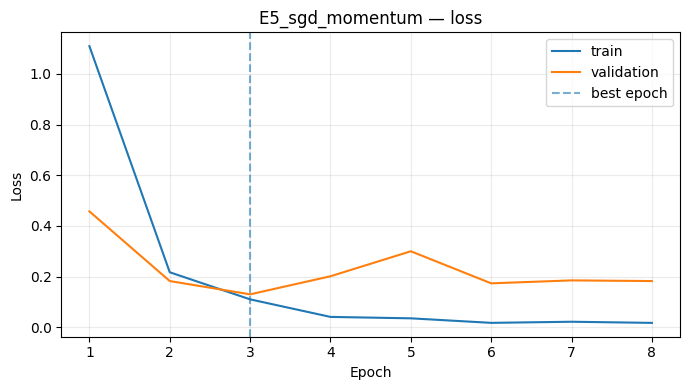

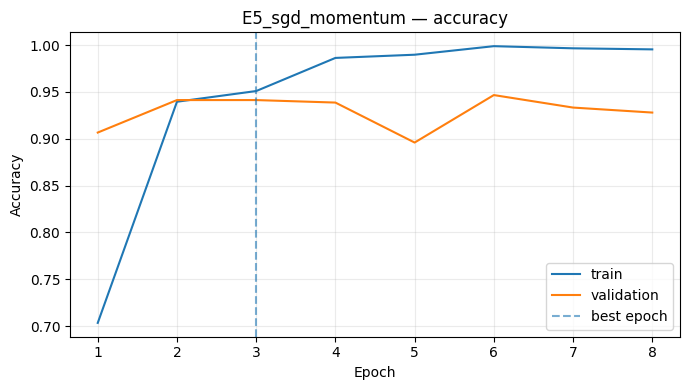

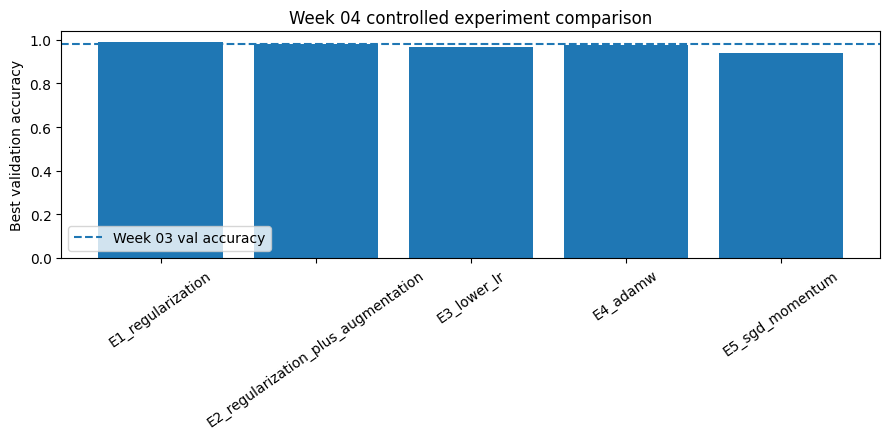

In [12]:
for r in experiment_results:
    h = r["history"]
    epochs = np.arange(1, len(h["val_loss"]) + 1)

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(epochs, h["train_loss"], label="train")
    ax.plot(epochs, h["val_loss"], label="validation")
    ax.axvline(r["best_epoch"], linestyle="--", alpha=0.6, label="best epoch")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Loss")
    ax.set_title(f"{r['name']} — loss")
    ax.legend(); ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"{r['name']}_loss.png", dpi=160, bbox_inches="tight")
    plt.show()

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(epochs, h["train_acc"], label="train")
    ax.plot(epochs, h["val_acc"], label="validation")
    ax.axvline(r["best_epoch"], linestyle="--", alpha=0.6, label="best epoch")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Accuracy")
    ax.set_title(f"{r['name']} — accuracy")
    ax.legend(); ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"{r['name']}_accuracy.png", dpi=160, bbox_inches="tight")
    plt.show()

plot_df = results_df.sort_values("best_val_loss").copy()
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(plot_df["name"], plot_df["best_val_accuracy"])
ax.axhline(WEEK3_BASELINE["best_val_accuracy"], linestyle="--", label="Week 03 val accuracy")
ax.set_ylabel("Best validation accuracy")
ax.set_title("Week 04 controlled experiment comparison")
ax.tick_params(axis="x", rotation=35)
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "experiment_comparison_val_accuracy.png", dpi=160, bbox_inches="tight")
plt.show()

## 12. Select the best experiment using validation only

Primary rule: **lowest validation loss**. Validation accuracy is reported as a secondary metric.

In [13]:
best_result = min(experiment_results, key=lambda r: r["best_val_loss"])
print("Selected experiment:", best_result["name"])
print("Best validation loss:", best_result["best_val_loss"])
print("Validation accuracy at selected checkpoint:", best_result["best_val_accuracy"])
print("Train-validation accuracy gap at selected checkpoint:", best_result["generalization_gap_at_best"])

Selected experiment: E1_regularization
Best validation loss: 0.032718222123260296
Validation accuracy at selected checkpoint: 0.9893333333333333
Train-validation accuracy gap at selected checkpoint: 0.010666666666666713


## 13. Final test evaluation — run once after selection

This is the only Week 04 model evaluated on the test set.

In [14]:
_, _, test_ds, _, _, test_loader = make_loaders(False)
final_model = RegularizedMLP(IMAGE_SIZE, N_CLASSES, dropout=best_result["dropout"]).to(DEVICE)
final_model.load_state_dict(torch.load(best_result["checkpoint"], map_location=DEVICE))
final_model.eval()

all_true, all_pred, all_conf = [], [], []
with torch.no_grad():
    for x, y in test_loader:
        x = x.to(DEVICE)
        logits = final_model(x)
        probs = torch.softmax(logits, dim=1)
        pred = probs.argmax(dim=1).cpu().numpy()
        conf = probs.max(dim=1).values.cpu().numpy()
        all_true.extend(y.numpy().tolist())
        all_pred.extend(pred.tolist())
        all_conf.extend(conf.tolist())

final_test_accuracy = accuracy_score(all_true, all_pred)
report_dict = classification_report(
    all_true, all_pred, target_names=class_names, output_dict=True, zero_division=0
)
print(f"Final Week 04 test accuracy: {final_test_accuracy:.4f}")
print(classification_report(all_true, all_pred, target_names=class_names, zero_division=0))

pred_df = test_df.copy().reset_index(drop=True)
pred_df["true_label"] = all_true
pred_df["pred_label"] = all_pred
pred_df["pred_class"] = [class_names[i] for i in all_pred]
pred_df["confidence"] = all_conf
pred_df["correct"] = pred_df["true_label"] == pred_df["pred_label"]
pred_df.to_csv(OUTPUT_DIR / "final_test_predictions.csv", index=False)

final_metrics = {
    "selected_experiment": best_result["name"],
    "selected_config": {k: v for k, v in best_result.items() if k not in ["history"]},
    "week03_baseline": WEEK3_BASELINE,
    "selected_obj_ids": SELECTED_OBJ_IDS,
    "selected_class_names": class_names,
    "train_samples": len(train_df), "val_samples": len(val_df), "test_samples": len(test_df),
    "train_scenes": int(train_df["scene_id"].nunique()),
    "val_scenes": int(val_df["scene_id"].nunique()),
    "test_scenes": int(test_df["scene_id"].nunique()),
    "final_test_accuracy": float(final_test_accuracy),
    "test_accuracy_change_vs_week03": float(final_test_accuracy - WEEK3_BASELINE["test_accuracy"]),
    "classification_report": report_dict,
}
with open(OUTPUT_DIR / "week04_metrics.json", "w", encoding="utf-8") as f:
    json.dump(final_metrics, f, indent=2)

Final Week 04 test accuracy: 0.4178
                 precision    recall  f1-score   support

tomato_soup_can       0.41      0.49      0.45       150
      sugar_box       0.71      0.39      0.50        75
master_chef_can       1.00      0.91      0.95        75
  tuna_fish_can       0.11      0.08      0.09        75
bleach_cleanser       0.11      0.15      0.12        75

       accuracy                           0.42       450
      macro avg       0.47      0.40      0.42       450
   weighted avg       0.46      0.42      0.43       450



## 14. Confusion matrix and representative predictions

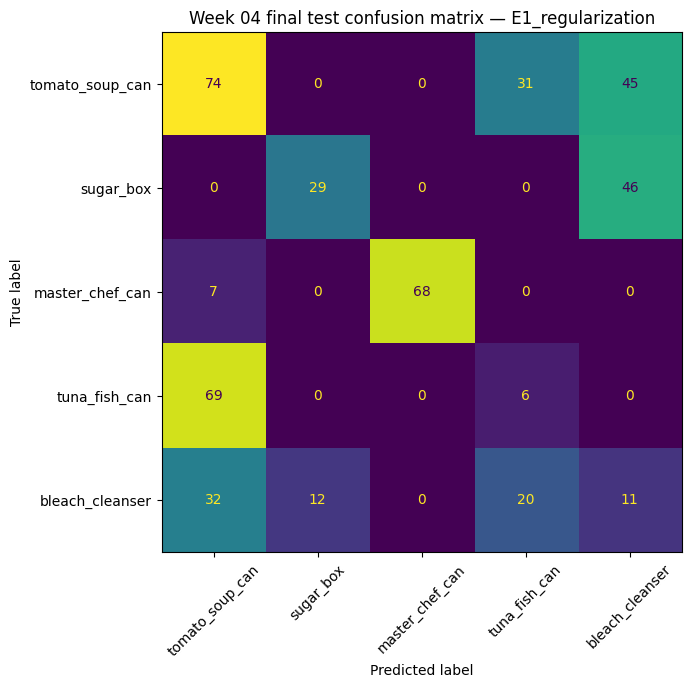

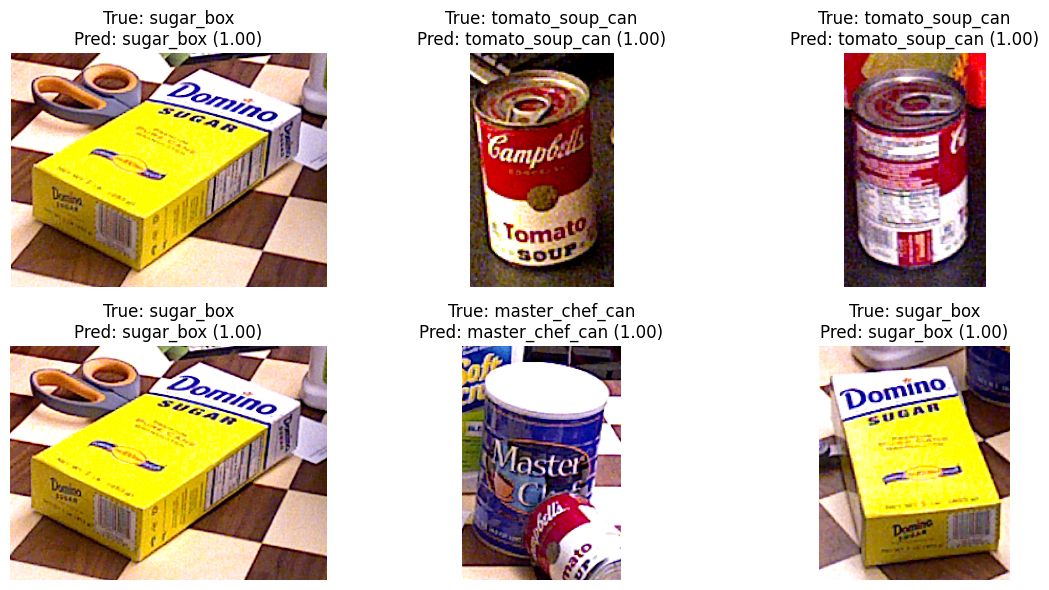

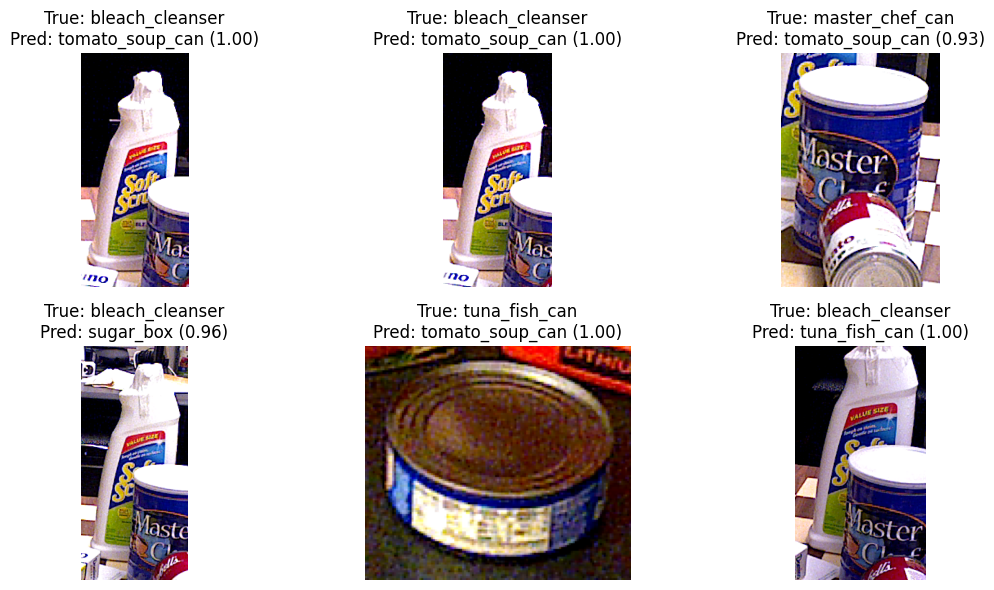

In [15]:
cm = confusion_matrix(all_true, all_pred, labels=list(range(N_CLASSES)))
fig, ax = plt.subplots(figsize=(7, 7))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, xticks_rotation=45, colorbar=False)
ax.set_title(f"Week 04 final test confusion matrix — {best_result['name']}")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "final_confusion_matrix.png", dpi=160, bbox_inches="tight")
plt.show()

def show_prediction_examples(pred_df, correct_value, n=6, filename="examples.png"):
    candidates = pred_df[pred_df["correct"] == correct_value]
    if len(candidates) == 0:
        print("No samples available for:", correct_value)
        return
    sample = candidates.head(n)
    fig, axes = plt.subplots(2, math.ceil(n / 2), figsize=(12, 6))
    axes = np.array(axes).reshape(-1)
    for ax in axes:
        ax.axis("off")
    for ax, (_, row) in zip(axes, sample.iterrows()):
        ax.imshow(crop_object(row))
        ax.set_title(
            f"True: {row['class_name']}\n"
            f"Pred: {row['pred_class']} ({row['confidence']:.2f})"
        )
        ax.axis("off")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()

show_prediction_examples(pred_df, True, filename="correct_predictions.png")
show_prediction_examples(pred_df, False, filename="wrong_predictions.png")

## 15. Automatic interpretation summary

This cell prints evidence-backed statements for the report. It does not claim that a change helped unless the measured validation/test values support it.

In [16]:
val_loss_delta = WEEK3_BASELINE["best_val_loss"] - best_result["best_val_loss"]
val_acc_delta = best_result["best_val_accuracy"] - WEEK3_BASELINE["best_val_accuracy"]
test_delta = final_test_accuracy - WEEK3_BASELINE["test_accuracy"]

print("=== WEEK 04 REPORT VALUES ===")
print("Selected classes:", ", ".join(class_names))
print("Selected experiment:", best_result["name"])
print("Optimizer:", best_result["optimizer"])
print("Learning rate:", best_result["lr"])
print("Dropout:", best_result["dropout"])
print("Weight decay:", best_result["weight_decay"])
print("Augmentation:", best_result["augmentation"])
print("Best epoch:", best_result["best_epoch"])
print(f"Best validation loss: {best_result['best_val_loss']:.4f}")
print(f"Validation accuracy: {best_result['best_val_accuracy']:.4f}")
print(f"Train accuracy at selected checkpoint: {best_result['train_acc_at_best']:.4f}")
print(f"Train-validation gap: {best_result['generalization_gap_at_best']:.4f}")
print(f"Final test accuracy: {final_test_accuracy:.4f}")
print(f"Change in val loss vs Week 03: {val_loss_delta:+.4f} (positive means lower/better Week 04 loss)")
print(f"Change in val accuracy vs Week 03: {val_acc_delta:+.4f}")
print(f"Change in test accuracy vs Week 03: {test_delta:+.4f}")

if test_delta > 0:
    print("Interpretation: the selected Week 04 setup improved held-out test accuracy relative to Week 03.")
elif test_delta < 0:
    print("Interpretation: validation-based tuning did not improve held-out test accuracy; scene/domain mismatch remains important.")
else:
    print("Interpretation: test accuracy was unchanged relative to Week 03.")

=== WEEK 04 REPORT VALUES ===
Selected classes: tomato_soup_can, sugar_box, master_chef_can, tuna_fish_can, bleach_cleanser
Selected experiment: E1_regularization
Optimizer: adam
Learning rate: 0.001
Dropout: 0.3
Weight decay: 0.0001
Augmentation: False
Best epoch: 7
Best validation loss: 0.0327
Validation accuracy: 0.9893
Train accuracy at selected checkpoint: 1.0000
Train-validation gap: 0.0107
Final test accuracy: 0.4178
Change in val loss vs Week 03: +0.0189 (positive means lower/better Week 04 loss)
Change in val accuracy vs Week 03: +0.0080
Change in test accuracy vs Week 03: -0.0955
Interpretation: validation-based tuning did not improve held-out test accuracy; scene/domain mismatch remains important.
